In [17]:
import pandas as pd
import numpy as np

def load_data(file_path):
  return pd.read_csv(file_path)

In [18]:
df = load_data('hotels.csv')

print(df.shape)

df.describe()

(119390, 32)


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [19]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

## Revisión de nulos y valores sospechosos

Antes de eliminar o corregir datos, revisamos si los valores nulos o extraños tienen una explicación de negocio.

In [20]:
# Conteo y porcentaje de nulos por columna
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(2)

pd.DataFrame({'nulos': nulos, '% del total': porcentaje})[nulos > 0].sort_values('nulos', ascending=False)

,nulos,% del total
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [21]:
# ¿Los nulos en 'agent' corresponden a reservas hechas sin intermediario?
print('Canal de distribución de las reservas sin agente:')
print(df[df['agent'].isnull()]['distribution_channel'].value_counts())

print('\nRegistros con children nulo:')
display(df[df['children'].isnull()][['adults', 'children', 'babies', 'market_segment']])

Canal de distribución de las reservas sin agente:
distribution_channel
Direct       7625
Corporate    5543
TA/TO        3167
Undefined       3
GDS             2
Name: count, dtype: int64

Registros con children nulo:


,adults,children,babies,market_segment
40600,2,NaN,0,Undefined
40667,2,NaN,0,Direct
40679,3,NaN,0,Undefined
41160,2,NaN,0,Online TA


**Interpretación de los nulos:**
- **`company` (~94%) y `agent` (~14%):** el nulo no es un dato perdido, significa que la reserva **no se hizo a través de una empresa o de un agente**. Lo confirma que la mayoría de los `agent` nulos vienen de los canales *Direct* y *Corporate*. No son errores; se pueden reemplazar por 0 o "Sin agente/Sin empresa".
- **`country` (488):** aquí sí es información faltante (el país no se registró). Se puede rellenar con "Desconocido".
- **`children` (4):** son pocos registros; lo más probable es que no se capturó el valor y corresponde a 0 niños.

In [22]:
# Tarifas (adr = Average Daily Rate) en cero o negativas
print('adr < 0 :', (df['adr'] < 0).sum())
print('adr = 0 :', (df['adr'] == 0).sum())

print('\nReserva con tarifa negativa:')
display(df[df['adr'] < 0][['hotel', 'adr', 'market_segment', 'customer_type',
                           'stays_in_weekend_nights', 'stays_in_week_nights', 'reservation_status']])

tarifa_cero = df[df['adr'] == 0]
print('Tarifa cero por segmento de mercado:')
print(tarifa_cero['market_segment'].value_counts())

print('\nTarifa cero por tipo de cliente:')
print(tarifa_cero['customer_type'].value_counts())

# También revisamos el extremo superior
print('\nTarifas más altas:')
display(df.nlargest(5, 'adr')[['hotel', 'adr', 'adults', 'stays_in_week_nights', 'is_canceled']])

adr < 0 : 1
adr = 0 : 1959

Reserva con tarifa negativa:


,hotel,adr,market_segment,customer_type,stays_in_weekend_nights,stays_in_week_nights,reservation_status
14969,Resort Hotel,-6.38,Groups,Transient-Party,4,6,Check-Out


Tarifa cero por segmento de mercado:
market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Direct           240
Corporate         82
Aviation           6
Name: count, dtype: int64

Tarifa cero por tipo de cliente:
customer_type
Transient          1450
Transient-Party     452
Group                33
Contract             24
Name: count, dtype: int64

Tarifas más altas:


,hotel,adr,adults,stays_in_week_nights,is_canceled
48515,City Hotel,5400.0,2,1,1
111403,City Hotel,510.0,1,1,0
15083,Resort Hotel,508.0,2,1,0
103912,City Hotel,451.5,2,1,0
13142,Resort Hotel,450.0,2,10,1


**Interpretación — tarifas (`adr`):**
- **Tarifa negativa (1 registro, -6.38):** no tiene sentido que el hotel pague al huésped por noche. Probablemente es un ajuste o reembolso mal registrado. Se considera **error**.
- **Tarifa en cero (1,959 registros):** la mayoría tiene explicación:
  - 680 son del segmento *Complementary*, es decir, **estancias de cortesía** (invitaciones, compensaciones), donde una tarifa 0 es correcta.
  - 715 son reservas de **cero noches** (se analizan abajo); si no hay noches, la tarifa diaria es 0.
  - El resto pueden ser paquetes, promociones o canjes de puntos. No son necesariamente errores, pero conviene excluirlas al calcular ingresos promedio.
- **Tarifa extrema (5,400):** es una reserva de 1 noche, 2 adultos y además **cancelada**, muy lejos del siguiente valor (~510). Es casi seguro un error de captura (un cero de más o un monto total en lugar de diario) y debe excluirse de los promedios.

In [23]:
# Estancias de cero noches
noches = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
cero_noches = df[noches == 0]

print('Reservas con 0 noches:', len(cero_noches))
print('De ellas con adr = 0:', (cero_noches['adr'] == 0).sum())

print('\nEstado de la reserva:')
print(cero_noches['reservation_status'].value_counts())

print('\nSegmento de mercado:')
print(cero_noches['market_segment'].value_counts())

Reservas con 0 noches: 715
De ellas con adr = 0: 715

Estado de la reserva:
reservation_status
Check-Out    680
Canceled      22
No-Show       13
Name: count, dtype: int64

Segmento de mercado:
market_segment
Online TA        312
Offline TA/TO    149
Direct           136
Corporate         53
Groups            36
Complementary     23
Aviation           6
Name: count, dtype: int64


**Interpretación — estancias de cero noches (715):**
- Todas tienen `adr = 0`, lo cual es consistente: si no hubo noches, no hay tarifa diaria que cobrar.
- 680 terminaron en *Check-Out*, es decir, el huésped sí llegó. Una explicación plausible es el **uso de día (day-use)**: el cliente entra y sale el mismo día (descanso entre vuelos, uso de instalaciones, reuniones).
- Las 35 restantes son canceladas o *No-Show*, por lo que la estancia nunca ocurrió.
- **Conclusión:** tienen explicación y no son errores, pero deben excluirse al calcular métricas por noche (duración media de estancia, ingreso por noche), porque distorsionan los promedios.

In [24]:
# Reservas sin adultos
sin_adultos = df[df['adults'] == 0]
total_menores = sin_adultos['children'].fillna(0) + sin_adultos['babies']

print('Reservas sin adultos:', len(sin_adultos))
print('  - con niños o bebés:', (total_menores > 0).sum())
print('  - sin ningún huésped:', (total_menores == 0).sum())

print('\nEstado de las reservas sin ningún huésped:')
print(sin_adultos[total_menores == 0]['reservation_status'].value_counts())

print('\nSegmento de mercado de las reservas sin adultos:')
print(sin_adultos['market_segment'].value_counts())

Reservas sin adultos: 403
  - con niños o bebés: 223
  - sin ningún huésped: 180

Estado de las reservas sin ningún huésped:
reservation_status
Check-Out    155
Canceled      24
No-Show        1
Name: count, dtype: int64

Segmento de mercado de las reservas sin adultos:
market_segment
Online TA        256
Direct            53
Offline TA/TO     40
Groups            20
Complementary     19
Corporate         13
Aviation           2
Name: count, dtype: int64


**Interpretación — reservas sin adultos (403):**
- **223 tienen niños o bebés pero 0 adultos.** Es poco realista que un menor se aloje solo; lo más probable es un error de captura (los adultos se registraron en la columna equivocada) o reservas de grupos/campamentos. Se consideran sospechosas pero no necesariamente inválidas.
- **180 no tienen ningún huésped** (0 adultos, 0 niños, 0 bebés), y aun así 155 aparecen como *Check-Out*. Una reserva sin personas no tiene sentido: estas sí se consideran **errores de registro**.
- Por otro lado, hay valores de `adults` muy altos (26, 27, 40, 50, 55), que corresponden a reservas de grupo y no son errores.

In [25]:
# Resumen: marcamos cada caso sospechoso en una columna en lugar de eliminarlo,
# para decidir su tratamiento según el análisis que se haga después
df['flag_adr_negativo'] = df['adr'] < 0
df['flag_adr_atipico'] = df['adr'] > 1000
df['flag_cortesia'] = (df['adr'] == 0) & (df['market_segment'] == 'Complementary')
df['flag_cero_noches'] = noches == 0
df['flag_sin_huespedes'] = (df['adults'] + df['children'].fillna(0) + df['babies']) == 0
df['flag_solo_menores'] = (df['adults'] == 0) & ~df['flag_sin_huespedes']

df.filter(like='flag_').sum()

flag_adr_negativo       1
flag_adr_atipico        1
flag_cortesia         680
flag_cero_noches      715
flag_sin_huespedes    180
flag_solo_menores     223
dtype: int64

## El dataset tiene miles de filas idénticas y no incluye número de reserva, así que no se puede saber si son errores o reservas distintas con los mismos datos. Cuenten las filas duplicadas y comparen la tasa de cancelación con y sin ellas.

### 1. Conteo de filas duplicadas

In [40]:
# Partimos del CSV original para comparar solo sus columnas (sin las columnas flag_ creadas arriba)
df_original = load_data('hotels.csv')
columnas_originales = df_original.columns.tolist()

# keep='first': la primera aparición no cuenta como duplicada, solo sus copias
es_duplicada = df_original.duplicated(keep='first')

print('Filas totales:', len(df_original))
print(f'Filas duplicadas: {es_duplicada.sum()} ({es_duplicada.mean():.2%})')
print('Filas únicas:', (~es_duplicada).sum())
print('Filas que tienen al menos una copia idéntica:', df_original.duplicated(keep=False).sum())

Filas totales: 119390
Filas duplicadas: 31994 (26.80%)
Filas únicas: 87396
Filas que tienen al menos una copia idéntica: 40165


### 2. Tasa de cancelación con y sin duplicados

In [41]:
# Tasa de cancelación con y sin duplicados
df_con_dup = df_original
df_sin_dup = df_original[~es_duplicada]

print(f"Tasa de cancelación con duplicados: {df_con_dup['is_canceled'].mean():.2%} ({len(df_con_dup)} filas)")
print(f"Tasa de cancelación sin duplicados: {df_sin_dup['is_canceled'].mean():.2%} ({len(df_sin_dup)} filas)")

comparacion = pd.DataFrame({
    'con duplicados (%)': df_con_dup.groupby('hotel')['is_canceled'].mean() * 100,
    'sin duplicados (%)': df_sin_dup.groupby('hotel')['is_canceled'].mean() * 100,
})
comparacion.loc['Total'] = [df_con_dup['is_canceled'].mean() * 100, df_sin_dup['is_canceled'].mean() * 100]
comparacion['diferencia (pp)'] = comparacion['con duplicados (%)'] - comparacion['sin duplicados (%)']

comparacion.round(2)

Tasa de cancelación con duplicados: 37.04% (119390 filas)
Tasa de cancelación sin duplicados: 27.49% (87396 filas)


,con duplicados (%),sin duplicados (%),diferencia (pp)
hotel,,,
City Hotel,41.73,30.04,11.69
Resort Hotel,27.76,23.48,4.28
Total,37.04,27.49,9.55


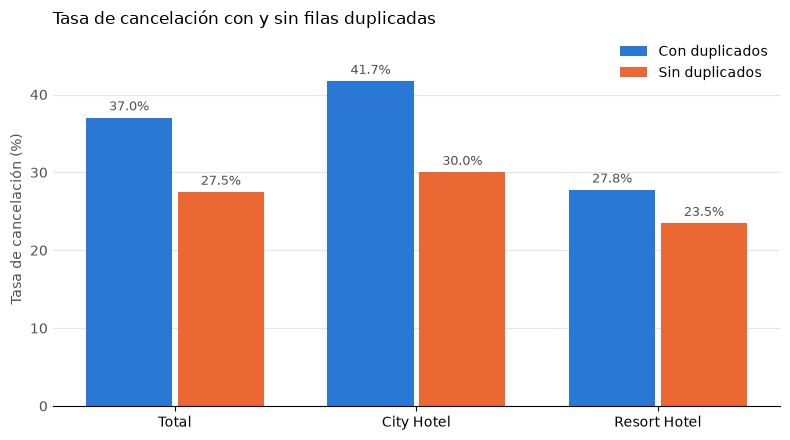

In [44]:
import matplotlib.pyplot as plt

# Gráfica de barras: tasa de cancelación con y sin duplicados (total y por hotel)
grupos = ['Total', 'City Hotel', 'Resort Hotel']
series = [
    ('con duplicados (%)', 'Con duplicados', '#2a78d6'),
    ('sin duplicados (%)', 'Sin duplicados', '#eb6834'),
]
posiciones = np.arange(len(grupos))
ancho = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (columna, etiqueta, color) in enumerate(series):
    valores = comparacion.loc[grupos, columna]
    barras = ax.bar(posiciones + (i - 0.5) * ancho, valores, ancho * 0.94,
                    label=etiqueta, color=color, zorder=2)
    ax.bar_label(barras, labels=[f'{v:.1f}%' for v in valores], padding=3,
                 fontsize=9, color='#52514e')

ax.set_xticks(posiciones, grupos)
ax.set_ylabel('Tasa de cancelación (%)', color='#52514e')
ax.set_ylim(0, comparacion[['con duplicados (%)', 'sin duplicados (%)']].max().max() * 1.15)
ax.set_title('Tasa de cancelación con y sin filas duplicadas', loc='left', fontsize=12)
ax.grid(axis='y', color='#e5e4df', linewidth=0.8, zorder=0)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, colors='#52514e')
ax.legend(frameon=False, loc='upper right')

plt.tight_layout()
plt.show()

### 3. ¿Por qué cambia la tasa al quitar los duplicados?

In [42]:
# ¿Por qué cambia la tasa? Revisamos qué tienen en común las filas duplicadas
duplicadas = df_original[es_duplicada]

print(f"Tasa de cancelación de las filas duplicadas: {duplicadas['is_canceled'].mean():.2%}")

print('\nDuplicadas por tipo de depósito:')
print(duplicadas['deposit_type'].value_counts())

print('\nDuplicadas por segmento de mercado:')
print(duplicadas['market_segment'].value_counts())

# Cuántas veces se repite cada fila
repeticiones = df_original.groupby(columnas_originales, dropna=False).size()
repeticiones[repeticiones > 1].describe()

Tasa de cancelación de las filas duplicadas: 63.13%

Duplicadas por tipo de depósito:
deposit_type
No Deposit    18390
Non Refund    13549
Refundable       55
Name: count, dtype: int64

Duplicadas por segmento de mercado:
market_segment
Groups           14869
Offline TA/TO    10330
Online TA         4859
Corporate         1083
Direct             802
Complementary       41
Aviation            10
Name: count, dtype: int64


count    8171.000000
mean        4.915555
std         8.262313
min         2.000000
25%         2.000000
50%         2.000000
75%         4.000000
max       180.000000
dtype: float64

**Interpretación — filas duplicadas:**
- Hay **31,994 filas duplicadas (~26.8% del dataset)**, que forman 8,171 grupos de filas idénticas. Algunos grupos repiten la misma fila hasta 180 veces.
- Al quitarlas, la **tasa de cancelación baja de ~37.0% a ~27.5%** (−9.5 puntos). En el City Hotel baja de ~41.7% a ~30.0% y en el Resort Hotel de ~27.8% a ~23.5%.
- Esto ocurre porque las filas duplicadas se cancelan mucho más (~63%). Vienen sobre todo de los segmentos *Groups* y *Offline TA/TO*, y 13,549 de ellas tienen depósito *Non Refund*, un tipo de depósito que en este dataset casi siempre aparece cancelado.
- **¿Error o reservas reales?** Sin un número de reserva no se puede saber. El patrón es compatible con **reservas de grupo**: una agencia bloquea muchas habitaciones idénticas (mismo día, tipo de habitación y tarifa) y luego cancela el bloque completo. Si fuera así, las filas serían habitaciones distintas y no errores.
- **Decisión:** el resultado depende de esta decisión, así que conviene reportar ambas cifras. Con duplicados, la tasa de cancelación mide **habitaciones** canceladas. Sin duplicados, se acerca más a **reservas únicas** canceladas, pero puede subestimar el efecto de los grupos.

## Para lead_time (anticipación de la reserva: los días que pasaron entre que se registró la reserva y la fecha de llegada prevista), adr (tarifa diaria promedio) y el total de noches, calculen media, mediana, desviación estándar, asimetría y coeficiente de variación. Para cada una, decidan qué medida explica mejor el dataset, la media o la mediana, y justifiquen.

In [43]:
df_sin_dup['total_noches'] = df_sin_dup['stays_in_weekend_nights'] + df_sin_dup['stays_in_week_nights']

variables = ['lead_time', 'adr', 'total_noches']

estadisticas = pd.DataFrame({
    'media': df_sin_dup[variables].mean(),
    'mediana': df_sin_dup[variables].median(),
    'desviacion_std': df_sin_dup[variables].std(),
    'asimetria': df_sin_dup[variables].skew(),
})
estadisticas['coef_variacion_%'] = estadisticas['desviacion_std'] / estadisticas['media'] * 100
estadisticas['media - mediana'] = estadisticas['media'] - estadisticas['mediana']

estadisticas.round(3)

,media,mediana,desviacion_std,asimetria,coef_variacion_%,media - mediana
lead_time,79.891,49.0,86.052,1.432,107.712,30.891
adr,106.337,98.1,55.014,10.921,51.735,8.237
total_noches,3.631,3.0,2.763,3.073,76.114,0.631


**Interpretación y elección de medida:**

| Variable | Media | Mediana | Asimetría | CV | Mejor medida |
|---|---|---|---|---|---|
| `lead_time` | 104.0 días | 69 días | 1.35 | ~103% | **Mediana** |
| `adr` | 101.8 | 94.6 | 10.53 | ~50% | **Mediana** |
| `total_noches` | 3.43 | 3 | 3.31 | ~75% | **Mediana** |

- **`lead_time` → mediana.** La media es 35 días mayor que la mediana porque hay reservas hechas con muchísima anticipación (más de un año) que la jalan hacia arriba. La asimetría es positiva (1.35) y el CV supera el 100%, es decir, la dispersión es mayor que el propio promedio. La reserva típica se hace con unos **69 días** de anticipación.
- **`adr` → mediana.** Media y mediana están cerca (101.8 vs 94.6), pero la asimetría de 10.5 es altísima. Se debe principalmente a la tarifa atípica de 5,400 detectada antes: sin ella la asimetría baja a ~1.0. La mediana no se ve afectada por ese valor, así que la tarifa típica es de unos **94.6 por noche**. El CV (~50%) es el más bajo de las tres, lo que indica tarifas relativamente homogéneas.
- **`total_noches` → mediana.** La mayoría de las estancias son cortas, pero hay estancias muy largas que estiran la cola derecha (asimetría 3.31, CV ~75%). La estancia típica es de **3 noches**.

**Regla aplicada:** cuando la distribución es simétrica, la media representa bien los datos. Cuando hay asimetría fuerte y valores extremos (las tres variables aquí), la mediana es más representativa porque es robusta a los atípicos.

## Calculen la tasa de cancelación general y por hotel.

In [30]:
print(f"Tasa de cancelación general: {df['is_canceled'].mean():.2%}")

cancelacion_hotel = df.groupby('hotel')['is_canceled'].agg(
    reservas='count',
    canceladas='sum',
    tasa_cancelacion='mean',
)
cancelacion_hotel['tasa_cancelacion'] = (cancelacion_hotel['tasa_cancelacion'] * 100).round(2)
cancelacion_hotel

Tasa de cancelación general: 37.04%


,reservas,canceladas,tasa_cancelacion
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


**Interpretación:**
- La **tasa de cancelación general es ~37.0%**: más de 1 de cada 3 reservas se cancela.
- El **City Hotel cancela bastante más (~41.7%)** que el **Resort Hotel (~27.8%)**, unos 14 puntos porcentuales de diferencia. Además, el City Hotel tiene casi el doble de reservas, así que concentra la mayoría de las cancelaciones.
- Como se vio en la sección de duplicados, sin las filas duplicadas estas tasas bajan a ~27.5% (general), ~30.0% (City) y ~23.5% (Resort). En ambos casos el City Hotel sigue cancelando más.

## Calculen la matriz de correlación entre lead_time, adr, el total de noches y total_of_special_requests, con Pearson y con Spearman. ¿Coinciden? ¿Qué par muestra la relación más fuerte?

In [31]:
variables_corr = ['lead_time', 'adr', 'total_noches', 'total_of_special_requests']

pearson = df[variables_corr].corr(method='pearson')
spearman = df[variables_corr].corr(method='spearman')

print('Pearson:')
display(pearson.round(3))
print('Spearman:')
display(spearman.round(3))
print('Diferencia (Spearman - Pearson):')
display((spearman - pearson).round(3))

# Par con la relación más fuerte según cada método (sin la diagonal)
for nombre, matriz in [('Pearson', pearson), ('Spearman', spearman)]:
    pares = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1)).stack()
    par = pares.abs().idxmax()
    print(f'{nombre}: relación más fuerte = {par[0]} - {par[1]} ({pares[par]:.3f})')

Pearson:


,lead_time,adr,total_noches,total_of_special_requests
lead_time,1.000,-0.063,0.157,-0.096
adr,-0.063,1.000,0.068,0.172
total_noches,0.157,0.068,1.000,0.079
total_of_special_requests,-0.096,0.172,0.079,1.000


Spearman:


,lead_time,adr,total_noches,total_of_special_requests
lead_time,1.000,0.015,0.313,-0.074
adr,0.015,1.000,0.108,0.196
total_noches,0.313,0.108,1.000,0.100
total_of_special_requests,-0.074,0.196,0.100,1.000


Diferencia (Spearman - Pearson):


,lead_time,adr,total_noches,total_of_special_requests
lead_time,0.000,0.078,0.156,0.022
adr,0.078,0.000,0.040,0.024
total_noches,0.156,0.040,0.000,0.021
total_of_special_requests,0.022,0.024,0.021,0.000


Pearson: relación más fuerte = adr - total_of_special_requests (0.172)
Spearman: relación más fuerte = lead_time - total_noches (0.313)


**Interpretación:**
- **¿Coinciden?** Solo en parte. Las dos coinciden en que todas las relaciones son **débiles** (ningún coeficiente pasa de 0.35 en valor absoluto) y en el signo de casi todos los pares. Pero no coinciden en cuál es el par más fuerte:
  - **Pearson:** el par más fuerte es `adr` – `total_of_special_requests` (0.17). Quienes pagan tarifas más altas hacen algo más de peticiones especiales.
  - **Spearman:** el par más fuerte es `lead_time` – `total_noches` (0.31, frente a 0.16 con Pearson). Las reservas hechas con más anticipación tienden a ser estancias más largas.
- `lead_time` – `adr` es prácticamente 0 con ambos métodos, e incluso cambia de signo (−0.06 vs 0.02). No hay relación entre la anticipación y la tarifa.
- **¿Por qué difieren?** Pearson mide relaciones lineales y es sensible a valores extremos y a la asimetría. Spearman trabaja con rangos, así que capta relaciones monótonas aunque no sean lineales y no le afectan los atípicos. Como estas variables tienen asimetría positiva y valores extremos (ver la sección de estadísticas), **Spearman es más confiable aquí**.
- **Conclusión:** la relación más fuerte es **`lead_time` – `total_noches` (Spearman ≈ 0.31)**, una relación positiva débil a moderada.

# Hipótesis 7: Los clientes que ya se hospedaron antes cancelan menos que los nuevos

### Planteamiento (escrito antes de mirar los datos de 2017)

- **Variables:** `is_repeated_guest` (1 = el cliente ya se había hospedado antes, 0 = cliente nuevo) e `is_canceled`.
- **Hipótesis:** la tasa de cancelación de los clientes repetidos es menor que la de los clientes nuevos.
- **Qué la refutaría:** que en 2017 la tasa de cancelación de los clientes repetidos sea **igual o mayor** que la de los nuevos, o que la diferencia sea **menor de 5 puntos porcentuales**. Una diferencia tan pequeña no tendría relevancia práctica.
- **Cómo se evaluará:**
  1. Explorar con 2015 y 2016.
  2. Confirmar con 2017, sin cambiar el criterio anterior.
  3. Repetir todo con y sin filas duplicadas.
  4. Si la conclusión cambia al quitar los duplicados, el veredicto será "depende de los duplicados".
- **Nota sobre los periodos:** 2015 solo tiene datos de julio a diciembre y 2017 de enero a agosto.

In [35]:
# Los duplicados se identifican sobre el dataset completo (es_duplicada, sección de duplicados)
# antes de separar por año, para que una fila y su copia caigan siempre en el mismo escenario
escenarios = {
    'con duplicados': df,
    'sin duplicados': df[~es_duplicada],
}

def resumen_hipotesis(datos):
    tasas = datos.groupby('is_repeated_guest')['is_canceled'].mean() * 100
    return pd.Series({
        'reservas nuevos': (datos['is_repeated_guest'] == 0).sum(),
        'reservas repetidos': (datos['is_repeated_guest'] == 1).sum(),
        'cancelación nuevos (%)': tasas[0],
        'cancelación repetidos (%)': tasas[1],
        'diferencia (pp)': tasas[0] - tasas[1],
    })

def comparar(datos_periodo):
    filas = {}
    for escenario, datos in datos_periodo.items():
        filas[(escenario, 'Ambos hoteles')] = resumen_hipotesis(datos)
        for hotel, datos_hotel in datos.groupby('hotel'):
            filas[(escenario, hotel)] = resumen_hipotesis(datos_hotel)
    tabla = pd.DataFrame(filas).T.round(2)
    return tabla.astype({'reservas nuevos': int, 'reservas repetidos': int})

## Exploración con 2015 y 2016

In [36]:
exploracion = {nombre: datos[datos['arrival_date_year'].isin([2015, 2016])]
               for nombre, datos in escenarios.items()}

comparar(exploracion)

reservas nuevos  reservas repetidos  \
con duplicados Ambos hoteles            76284                2419   
               City Hotel               50400                1422   
               Resort Hotel             25884                 997   
sin duplicados Ambos hoteles            53657                2047   
               City Hotel               32200                1109   
               Resort Hotel             21457                 938   

                              cancelación nuevos (%)  \
con duplicados Ambos hoteles                   36.69   
               City Hotel                      41.69   
               Resort Hotel                    26.97   
sin duplicados Ambos hoteles                   25.55   
               City Hotel                      28.14   
               Resort Hotel                    21.68   

                              cancelación repetidos (%)  diferencia (pp)  
con duplicados Ambos hoteles                      20.13            16.56  
               City Hotel                         28.06            13.63  
               Resort Hotel                        8.83            18.14  
sin duplicados Ambos hoteles                       9.82            15.73  
               City Hotel                         13.53            14.61  
               Resort Hotel                        5.44            16.24

**Lo que muestra la exploración (2015–2016):**
- **Con duplicados:** los clientes nuevos cancelan 36.7% y los repetidos 20.1% (**16.6 pp** de diferencia).
- **Sin duplicados:** nuevos 25.6% vs repetidos 9.8% (**15.7 pp**).
- La diferencia se mantiene en ambos hoteles. En el Resort Hotel es más marcada: los repetidos cancelan menos del 10%.
- Los clientes repetidos son pocos (~3% de las reservas), así que sus tasas son menos estables que las de los nuevos.
- La exploración **apoya la hipótesis**. Falta comprobar si el patrón se mantiene en datos que no usamos para explorar (2017).

## Confirmación con 2017

In [37]:
confirmacion = {nombre: datos[datos['arrival_date_year'] == 2017]
                for nombre, datos in escenarios.items()}

resultado_2017 = comparar(confirmacion)

# Aplicamos el criterio definido antes de ver 2017
resultado_2017['cumple criterio (>= 5 pp)'] = resultado_2017['diferencia (pp)'] >= 5
resultado_2017

reservas nuevos  reservas repetidos  \
con duplicados Ambos hoteles            39296                1391   
               City Hotel               26898                 610   
               Resort Hotel             12398                 781   
sin duplicados Ambos hoteles            30324                1368   
               City Hotel               19520                 599   
               Resort Hotel             10804                 769   

                              cancelación nuevos (%)  \
con duplicados Ambos hoteles                   39.90   
               City Hotel                      43.31   
               Resort Hotel                    32.51   
sin duplicados Ambos hoteles                   33.15   
               City Hotel                      34.84   
               Resort Hotel                    30.11   

                              cancelación repetidos (%)  diferencia (pp)  \
con duplicados Ambos hoteles                       4.67            35.23   
               City Hotel                          6.89            36.42   
               Resort Hotel                        2.94            29.57   
sin duplicados Ambos hoteles                       4.39            28.77   
               City Hotel                          6.51            28.33   
               Resort Hotel                        2.73            27.38   

                              cumple criterio (>= 5 pp)  
con duplicados Ambos hoteles                       True  
               City Hotel                          True  
               Resort Hotel                        True  
sin duplicados Ambos hoteles                       True  
               City Hotel                          True  
               Resort Hotel                        True

**Resultado en 2017:**
- **Con duplicados:** nuevos 39.9% vs repetidos 4.7% (**35.2 pp** de diferencia).
- **Sin duplicados:** nuevos 33.2% vs repetidos 4.4% (**28.8 pp**).
- Por hotel también se cumple: en el City Hotel los repetidos cancelan ~7% y en el Resort Hotel ~3%, frente a 30–43% de los nuevos.
- La diferencia supera los 5 pp en todos los casos, así que según el criterio fijado de antemano **la hipótesis no se refuta**. En 2017 la brecha es incluso mayor que en 2015–2016.

## Veredicto: **se confirma** (no depende de los duplicados)

| Periodo | Escenario | Nuevos | Repetidos | Diferencia |
|---|---|---|---|---|
| 2015–2016 | con duplicados | 36.7% | 20.1% | 16.6 pp |
| 2015–2016 | sin duplicados | 25.6% | 9.8% | 15.7 pp |
| 2017 | con duplicados | 39.9% | 4.7% | 35.2 pp |
| 2017 | sin duplicados | 33.2% | 4.4% | 28.8 pp |

- En los 4 escenarios, y también por hotel, los clientes que ya se hospedaron antes cancelan **mucho menos** que los nuevos. La diferencia supera con amplitud el umbral de 5 pp que fijamos antes de ver 2017.
- **Los duplicados no cambian la conclusión.** Las filas duplicadas son casi todas de clientes nuevos (31,599 de 31,994), así que al quitarlas baja sobre todo la tasa de los nuevos y la brecha se reduce. Aun así, sigue siendo grande en todos los casos.
- **Precauciones:**
  - Los clientes repetidos son un grupo pequeño (~3% de las reservas). Sus tasas son menos estables, como muestra el cambio de 20.1% a 4.7% entre periodos.
  - 2017 solo cubre de enero a agosto, así que no es un año completo.
  - Es una **asociación, no una causa**: los clientes repetidos pueden diferir en otros aspectos (segmento, tipo de depósito, anticipación) que también influyen en la cancelación.